In [11]:
# Questão 1 e 2. (Exploração Inicial e Tratamento de Dados).


import pandas as pd
import matplotlib.pyplot as plt

# Carregar arquivos de bases de dados.
df = pd.read_csv('vendas.csv', sep=';', encoding='utf-8')

# Removendo duplicados.
df = df.drop_duplicates()

# Preencher  para cidades vazias.
df['cidade_cliente'] = df['cidade_cliente'].fillna('Não informado')

df['categoria_produto'] = df['categoria_produto'].replace({
    'Eletronicos': 'Eletrônicos',
    'Informatica': 'Informática'
})

# Converter data e apagar datas inválidas.
df['data_venda'] = pd.to_datetime(df['data_venda'],errors='coerce')
df = df.dropna(subset=['data_venda'])

# Ficar aqui quantidades e valores mais.
df = df[df['quantidade'] > 0]
df = df[df['valor_total'] > 0]

print('Total de Registros depois limpeza:', len(df))






Total de Registros depois limpeza: 49552


In [3]:
# Questão 3. (Faturamento Total).

#Vamos filtrar para vendas concluidas.
concluidas = df[df['status_venda'] == 'Concluído']

# Vamos calcular faturamento bruto e líquido.
faturamento_bruto = (concluidas['preco_unitario']* concluidas['quantidade']).sum()
faturamento_liquido = concluidas['valor_total'].sum()

print('Faturamento Bruto: R$', round(faturamento_bruto, 2))
print('Faturamento Líquido: R$', round(faturamento_liquido, 2))

Faturamento Bruto: R$ 117190025.6
Faturamento Líquido: R$ 110386064.05


In [4]:
# Questão 4. (Volume de Vendas).

# Vamos somar quantidade vendida de cada produto e pegar os 10 maiores.
top10_produtos = concluidas.groupby('nome_produto')['quantidade'].sum().sort_values(ascending=False).head
(10)

print('Top 10 Produtos mais vendidos (em unidades):')
print(top10_produtos)

Top 10 Produtos mais vendidos (em unidades):
<bound method NDFrame.head of nome_produto
Teclado Mecânico RGB        4384
Monitor 27" 4K              4302
Smartphone Premium X        4258
Smartphone Básico Y         4256
Mouse Gamer 10k DPI         4252
Notebook Estudante          4214
Caixa de Som Portátil       4209
Smart TV 55" 4K             4168
Fone de Ouvido Bluetooth    4164
Notebook Ultra Pro          4163
Cabo USB-C 2m               4131
Tablet 10"                  4131
Smartwatch Fit Z            4103
Monitor 24" Full HD         4091
Carregador Super Rápido     4015
Name: quantidade, dtype: int64>


In [5]:
# Questão 5. (Desempenho por Categoria).

# Vamos somar o faturamento liquido por categoria.
fat_categoria = concluidas.groupby('categoria_produto')['valor_total'].sum().sort_values(ascending=False)

print('Faturamento por categoria:')
print(fat_categoria)

Faturamento por categoria:
categoria_produto
Informática    59347280.39
Eletrônicos    43603496.62
Acessórios      4481515.00
Áudio           2953772.04
Name: valor_total, dtype: float64


In [6]:
# Questão 6. (Sazonalidade e Evolução).

# Criar colunas de ano e ano-mês
concluidas = concluidas.copy()
concluidas['ano'] = concluidas['data_venda'].dt.year
concluidas['ano_mes'] = concluidas['data_venda'].dt.to_period('M').astype(str)

# Faturamento por ano e por mês
fat_ano = concluidas.groupby('ano')['valor_total'].sum()
fat_mes = concluidas.groupby('ano_mes')['valor_total'].sum()

print('Faturamento por ano:')
print(fat_ano)

print('\nMês de maior faturamento:', fat_mes.idxmax(), '- R$', round(fat_mes.max(), 2))
print('Mês de menor faturamento:', fat_mes.idxmin(), '- R$', round(fat_mes.min(), 2))



Faturamento por ano:
ano
2021    36866424.30
2022    36233731.49
2023    37285908.26
Name: valor_total, dtype: float64

Mês de maior faturamento: 2021-12 - R$ 4164758.49
Mês de menor faturamento: 2021-02 - R$ 2361780.41


In [7]:
# Questao 7

# Faturamento total por vendedor Top 5.
top5_vendedores = concluidas.groupby('nome_vendedor')['valor_total'].sum().sort_values(ascending=False).head(5)

# Quantidade de pedidos únicos por vendedor
pedidos_vendedor = concluidas.groupby('nome_vendedor')['id_pedido'].nunique()

print('Top 5 Vendedores e Ticket Médio por Pedido:')
for vendedor in top5_vendedores.index:
    total = top5_vendedores[vendedor]
    ticket_medio = total / pedidos_vendedor[vendedor]
    print(f'{vendedor} -> Faturamento: R$ {total:.2f} | Ticket Médio: R$ {ticket_medio:.2f}')

Top 5 Vendedores e Ticket Médio por Pedido:
Carlos Eduardo -> Faturamento: R$ 8112128.21 | Ticket Médio: R$ 4848.85
Fernanda Alves -> Faturamento: R$ 7844633.68 | Ticket Médio: R$ 4663.87
Otávio Borges -> Faturamento: R$ 7681155.83 | Ticket Médio: R$ 4791.74
Diana Souza -> Faturamento: R$ 7496791.16 | Ticket Médio: R$ 4659.29
Gabriel Gomes -> Faturamento: R$ 7442974.22 | Ticket Médio: R$ 4519.11


In [8]:
# Questão 8

# Calcular o percentual de cada forma de pagamento
pagamentos_pct = concluidas['forma_pagamento'].value_counts(normalize=True) * 100

print('Participação por forma de pagamento (%):')
print(pagamentos_pct.round(2))

Participação por forma de pagamento (%):
forma_pagamento
Cartão de Crédito    25.63
PIX                  25.28
Boleto               24.96
Cartão de Débito     24.14
Name: proportion, dtype: float64


In [9]:
# Questão 9

# Somar faturamento por estado (UF)
fat_estado = concluidas.groupby('estado_cliente')['valor_total'].sum().sort_values(ascending=False)

print('Faturamento por Estado (UF):')
print(fat_estado)

Faturamento por Estado (UF):
estado_cliente
PR    11601514.83
SC    11317702.67
SP    11100129.49
BA    11090637.00
MG    11078779.52
DF    11017610.37
RJ    11003544.49
PE    10966909.25
GO    10935427.91
RS    10273808.52
Name: valor_total, dtype: float64


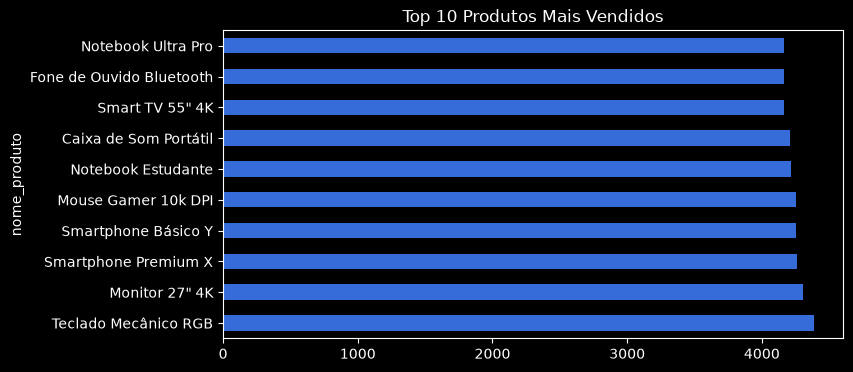

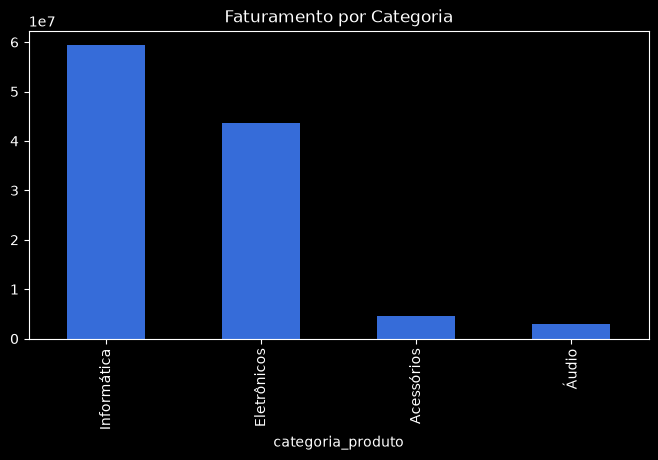

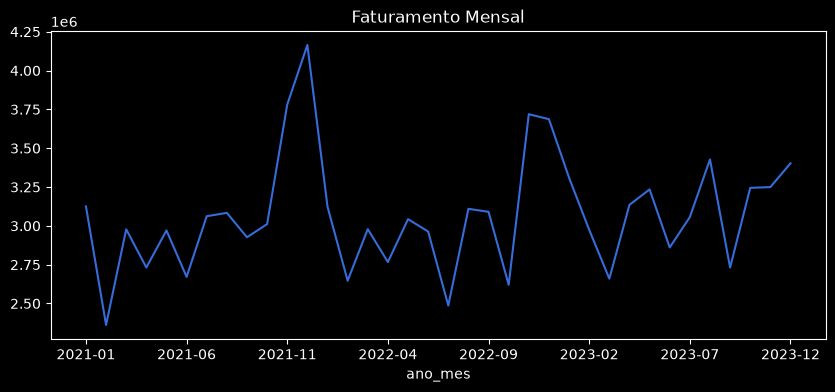

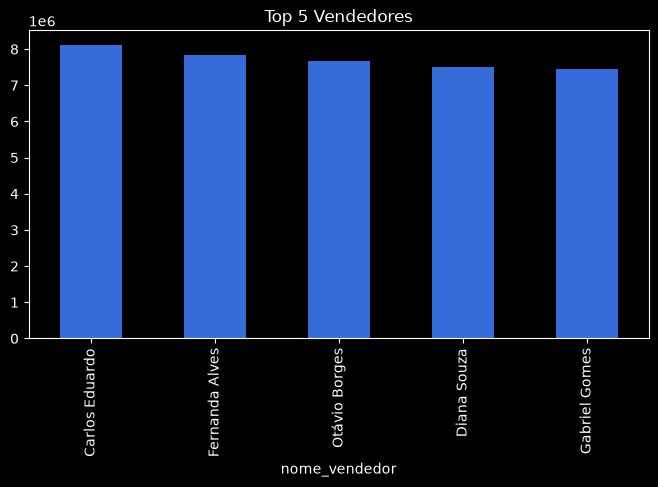

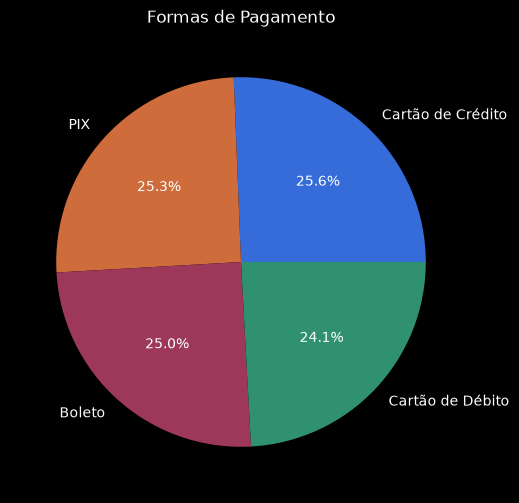

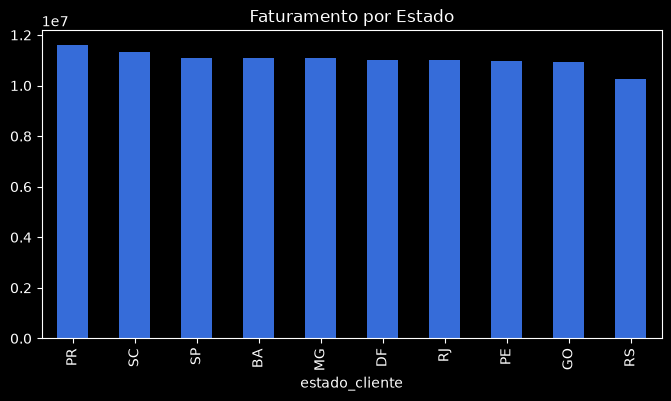

In [19]:
# Questão 10 - Os Graficos.

# Gráfico 1 - Produtos
plt.figure(figsize=(8, 4))
top10_produtos.plot(kind='barh')
plt.title('Top 10 Produtos Mais Vendidos')
plt.show()

# Gráfico 2 - Categorias
plt.figure(figsize=(8, 4))
fat_categoria.plot(kind='bar')
plt.title('Faturamento por Categoria')
plt.show()

# Gráfico 3 - Faturamento Mensal
plt.figure(figsize=(10, 4))
fat_mes.plot(kind='line')
plt.title('Faturamento Mensal')
plt.show()

# Gráfico 4 - Vendedores
plt.figure(figsize=(8, 4))
top5_vendedores.plot(kind='bar')
plt.title('Top 5 Vendedores')
plt.show()

# Gráfico 5 - Pagamentos
plt.figure(figsize=(6, 6))
pagamentos_pct.plot(kind='pie', autopct='%1.1f%%')
plt.title('Formas de Pagamento')
plt.ylabel('')
plt.show()

# Gráfico 6 - Estados
plt.figure(figsize=(8, 4))
fat_estado.plot(kind='bar')
plt.title('Faturamento por Estado')
plt.show()




In [20]:

print(type(concluidas))
print(concluidas.columns.tolist())
print(concluidas.head())

print(type(top10_produtos))


<class 'pandas.DataFrame'>
['id_item_venda', 'id_pedido', 'data_venda', 'nome_produto', 'categoria_produto', 'quantidade', 'preco_unitario', 'desconto', 'valor_total', 'nome_cliente', 'cidade_cliente', 'estado_cliente', 'nome_vendedor', 'forma_pagamento', 'status_venda', 'ano', 'ano_mes']
   id_item_venda  id_pedido data_venda          nome_produto  \
2              3      10001 2021-02-24       Smart TV 55" 4K   
3              4      10002 2022-11-28        Monitor 27" 4K   
4              5      10002 2022-11-28  Teclado Mecânico RGB   
5              6      10002 2022-11-28   Mouse Gamer 10k DPI   
6              7      10003 2023-01-11       Smart TV 55" 4K   

  categoria_produto  quantidade  preco_unitario  desconto  valor_total  \
2       Eletrônicos           1          3100.0    587.85      2512.15   
3       Informática           1          2100.0      0.00      2100.00   
4       Informática           1           550.0     69.14       480.86   
5       Informática          

categoria_produto  Acessórios  Eletrônicos  Informática      Áudio
estado_cliente                                                    
BA                  447005.66   4387070.92   5955361.75  301198.67
DF                  423699.14   4366496.16   5937611.50  289803.57
GO                  481568.79   4256136.27   5909033.16  288689.69
MG                  442242.24   4254164.64   6088511.26  293861.38
PE                  455376.01   4620220.26   5609262.69  282050.29
PR                  469761.51   4653306.24   6149894.11  328552.97
RJ                  451719.35   4453860.74   5833224.05  264740.35
RS                  437691.42   4104630.07   5436588.72  294898.31
SC                  417031.08   4148680.24   6430824.26  321167.09
SP                  455419.80   4358931.08   5996968.89  288809.72


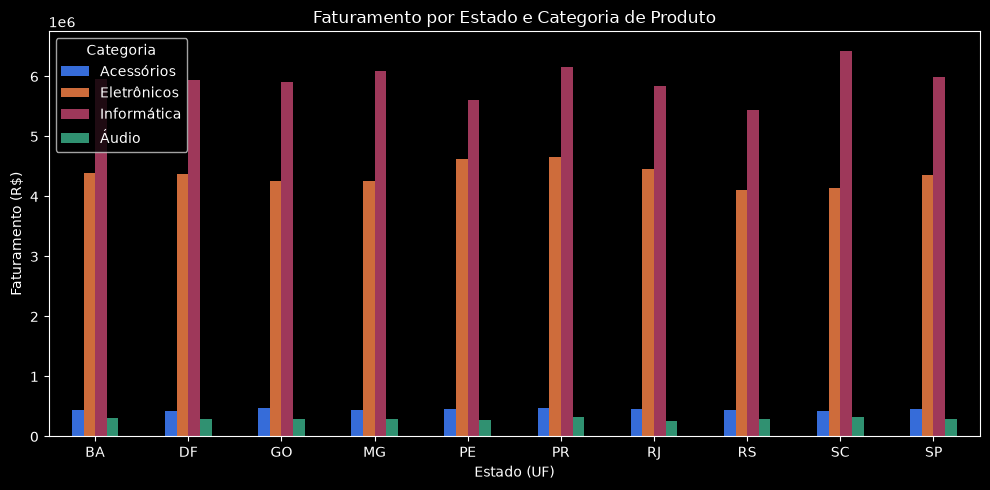

In [21]:
# Questão 11

# Cruzamento simples: Faturamento por Estado e Categoria
cruzamento = concluidas.groupby(['estado_cliente', 'categoria_produto'])['valor_total'].sum().unstack()
print(cruzamento)

# Gráfico do estudo aplicado
cruzamento.plot(kind='bar', figsize=(10, 5))
plt.title('Faturamento por Estado e Categoria de Produto')
plt.xlabel('Estado (UF)')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=0)
plt.legend(title='Categoria')
plt.tight_layout()
plt.show()